# Tutorial 6: experiments

So far each model ran with fixed operating conditions: a constant inlet temperature and
mass flow rate. An experiment operates a battery the way it is used or tested, as a
sequence of steps, such as "discharge at 2 kW until the outlet falls below 40 °C, rest for
an hour, then charge".

A heat battery has two controls, the inlet temperature and the mass flow rate. There are
three kinds of step:

- `Inlet` holds both controls;
- `Rest` stops the flow;
- `Power` holds the power, by adjusting the control you do not give.

Each step ends after its duration or when one of its termination conditions is met.
`run_experiment` runs the steps in order and returns an ordinary `pybamm.Solution`.

In [1]:
import numpy as np
import pybamm

import pytes
from pytes import plotting
from pytes.experiments import Experiment, run_experiment, step_description
from pytes.experiments import step as s

model = pytes.SharpFrontModel()
T_cold, T_hot = 273.15 + 10, 273.15 + 75

## A first experiment

Temperatures are in kelvin, mass flow rates in kg/s and times in seconds. This step is the default discharge of the earlier tutorials (see [Tutorial 2](tutorial_2_finned_tube_models.ipynb)), water at 10 °C and 0.02 kg/s, but it stops when
the outlet falls below 40 °C, the lowest useful temperature for hot water, instead of after
an hour.

In [2]:
discharge = s.Inlet(T_cold, 0.02, termination=s.outlet_temperature_below(273.15 + 40))
solution = run_experiment(model, Experiment([discharge]))
print(
    f"hot water for {solution['Time [min]'].entries[-1]:.0f} min, "
    f"{solution['Discharged energy [kWh]'].entries[-1]:.2f} kWh delivered"
)

hot water for 34 min, 1.90 kWh delivered


## Holding the power

A `Power` step holds the power of the battery, positive on discharge and negative on
charge. Give it one control and it adjusts the other. Here the inlet is held at 10 °C and
the flow adjusts to deliver 2 kW: it rises as the battery cools. The flow needed grows
without bound as the outlet approaches the inlet temperature, so the step also stops if the
flow exceeds 0.1 kg/s.

In [3]:
constant_power = s.Power(
    2e3,
    inlet_temperature=T_cold,
    termination=[
        s.outlet_temperature_below(273.15 + 40),
        s.mass_flow_rate_above(0.1),
    ],
)
power_solution = run_experiment(model, Experiment([constant_power]))
pybamm.dynamic_plot(
    power_solution,
    [
        ["Inlet temperature [degC]", "Outlet temperature [degC]"],
        "Mass flow rate [kg.s-1]",
        "Discharged energy [kWh]",
    ],
    time_unit="minutes",
);

interactive(children=(FloatSlider(value=0.0, description='t', max=59.032286442949705, step=0.590322864429497),…

## Cycles

Steps grouped in a tuple form a cycle, and a list of cycles can be repeated, as in PyBaMM.
This cycle discharges the battery at 2 kW, rests for half an hour, then charges it with
water at 75 °C and 0.02 kg/s, as a boiler or a heat pump would, until 95 % of the PCM is
liquid. A `description` names each step in the results.

In [4]:
charge = s.Inlet(
    T_hot,
    0.02,
    termination=s.average_liquid_fraction_above(0.95),
    description="Charge at 75 degC",
)
rest = s.Rest(duration=1800, description="Rest")
discharge = s.Power(
    2e3,
    inlet_temperature=T_cold,
    termination=[
        s.outlet_temperature_below(273.15 + 40),
        s.mass_flow_rate_above(0.1),
    ],
    description="Discharge at 2 kW",
)
experiment = Experiment([(discharge, rest, charge)] * 3)
cycles = run_experiment(model, experiment)

for i, cycle in enumerate(cycles.cycles, start=1):
    for step in cycle.steps:
        minutes = (step.t[-1] - step.t[0]) / 60
        print(f"cycle {i}: {step_description(step):18s} {minutes:5.1f} min")

cycle 1: Discharge at 2 kW   59.0 min
cycle 1: Rest                30.0 min
cycle 1: Charge at 75 degC  103.6 min
cycle 2: Discharge at 2 kW   57.3 min
cycle 2: Rest                30.0 min
cycle 2: Charge at 75 degC  107.2 min
cycle 3: Discharge at 2 kW   58.0 min
cycle 3: Rest                30.0 min
cycle 3: Charge at 75 degC  108.3 min


The whole experiment is one solution, so every plot of [Tutorial 5](tutorial_5_plotting.ipynb) applies to it.
`solution.cycles` holds one solution per cycle, and `cycle.steps` one per step.

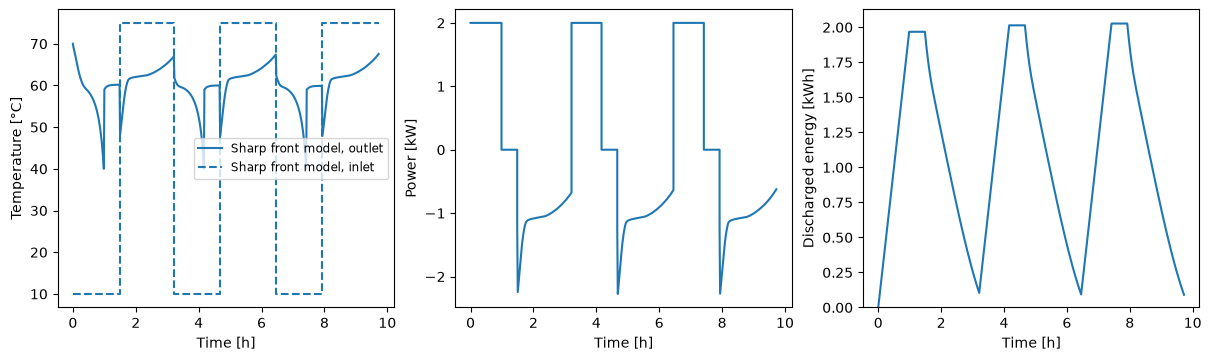

In [5]:
fig, axes = plotting.plot_summary(cycles)

The battery starts uniform at 70 °C, and each charge ends at a slightly different state,
so the discharges differ by a minute or two. During each charge the power is negative,
and the discharged energy falls back as the battery takes energy in.

## Time-varying conditions

A step value can also be a time series, as a 2-column array of time since the start of
the step and value, interpolated linearly, or a function of that time. Here the battery
supplies two draws of hot water in an hour, each of 15 minutes at 0.02 kg/s.
Between the draws there is no flow, and the water left in the tube is warmed again by the
PCM around it.

In [6]:
draws = np.array(
    [
        [0, 0.02],
        [900, 0.02],
        [901, 0],
        [1800, 0],
        [1801, 0.02],
        [2700, 0.02],
        [2701, 0],
        [3600, 0],
    ]
)
draw_solution = run_experiment(model, Experiment([s.Inlet(T_cold, draws, period=10)]))
pybamm.dynamic_plot(
    draw_solution,
    [
        ["Inlet temperature [degC]", "Outlet temperature [degC]"],
        "Mass flow rate [kg.s-1]",
        "Power [kW]",
        "Discharged energy [kWh]",
    ],
    time_unit="minutes",
);

interactive(children=(FloatSlider(value=0.0, description='t', max=60.0, step=0.6), Output()), _dom_classes=('w…

Experiments work the same way for every model. See the
[experiments](../experiments.ipynb) example for the throughputs and the round-trip
efficiency over cycles, and the [design study](../design_study.ipynb) for an experiment
used to compare a finned-tube battery with a packed bed.